# Taller: Programación Orientada a Objetos para Gestión de Datos
**Bootcamp PY4 — Python y Manipulación de Datos**
**Jhonnatan Peñate**

---

En este taller construyo paso a paso un pipeline de datos completo aplicando
los cuatro pilares de la POO:

- **Abstracción** — definir contratos que todas las piezas deben cumplir.
- **Herencia** — reutilizar y extender comportamiento entre clases.
- **Encapsulamiento** — proteger los datos internos de cada componente.
- **Polimorfismo** — intercambiar piezas sin romper el resto del sistema.

Al final del taller habré construido esta arquitectura:

```
DataComponent (abstracta)
       |
  +-----------+
  |           |
DataLoader  DataCleaner  ← también usan ValidatorMixin + LoggerMixin
                |
           DataAnalyst
```

---
## Configuración inicial

Antes de empezar, vamos a importar todo lo que vamos a necesitar durante el taller y a crear el dataset de ejemplo con el que trabajaremos.


In [41]:
# Instalacion de dependencias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from abc import ABC, abstractmethod
import os

print("Librerias cargadas correctamente.")


Librerias cargadas correctamente.


## Configuración inicial

Importo todas las librerías necesarias para el pipeline. `abc` me permite
definir clases abstractas, `os` maneja rutas de archivos, y pandas +
matplotlib/seaborn cubren la capa de análisis y visualización.

In [42]:
# Creamos un CSV de ventas con valores nulos y tipos mixtos para practicar limpieza
np.random.seed(42)
n = 200

data = {
    "fecha": pd.date_range("2024-01-01", periods=n, freq="D").astype(str),
    "producto": np.random.choice(["Laptop", "Mouse", "Teclado", "Monitor", None], n),
    "categoria": np.random.choice(["Electronica", "Accesorios", "Perifericos"], n),
    "cantidad": np.random.randint(1, 20, n).astype(float),
    "precio_unitario": np.round(np.random.uniform(10, 1500, n), 2),
    "region": np.random.choice(["Norte", "Sur", "Centro", None], n),
}

# Introducimos algunos nulos artificiales
df_raw = pd.DataFrame(data)
df_raw.loc[np.random.choice(df_raw.index, 15, replace=False), "cantidad"] = np.nan
df_raw.loc[np.random.choice(df_raw.index, 10, replace=False), "precio_unitario"] = np.nan

# Guardamos el CSV
df_raw.to_csv("ventas.csv", index=False)
print(f"Archivo 'ventas.csv' creado con {len(df_raw)} filas.")
print(df_raw.head())


Archivo 'ventas.csv' creado con 200 filas.
        fecha producto    categoria  cantidad  precio_unitario  region
0  2024-01-01  Monitor   Accesorios      19.0           945.06  Centro
1  2024-01-02     None   Accesorios      17.0           880.63     Sur
2  2024-01-03  Teclado   Accesorios      19.0          1352.73   Norte
3  2024-01-04     None  Perifericos       5.0            77.72     Sur
4  2024-01-05     None  Perifericos       9.0           428.64  Centro


---
# Fase 1: Arquitectura Base y Mixins

Antes de escribir una sola linea de logica de negocio, vamos a definir la **arquitectura** del sistema. Esto es pensar como ingenieros: primero el contrato, luego la implementacion.

## Paso 1: La clase abstracta `DataComponent`

Una **clase abstracta** es como un contrato firmado. Le dice a cualquier clase que la herede: *"si quieres formar parte de este sistema, debes implementar el metodo `execute()`"*.

En Python usamos el modulo `abc` (Abstract Base Classes):
- `ABC` — hace que la clase sea abstracta.
- `@abstractmethod` — marca metodos que las subclases **estan obligadas** a implementar.

**Por que nos sirve esto en un pipeline?**  
Porque despues podemos tratar a `DataLoader`, `DataCleaner` y `DataAnalyst` como si fueran el mismo tipo de objeto y llamar `.execute()` en todos sin saber los detalles internos.


In [43]:
# Paso 1: Clase abstracta DataComponent
# ---------------------------------------------------------------------------

class DataComponent(ABC):
    """
    Contrato base del pipeline. Cualquier clase que herede de aquí
    está obligada a implementar el método execute().
    """
    @abstractmethod
    def execute(self):
        pass

**Prueba rapida:** intenta instanciar `DataComponent()` directamente. Deberias obtener un `TypeError`. Esto confirma que el contrato funciona.


In [44]:

# Prueba: instanciar DataComponent directamente debe lanzar TypeError
try:
    DataComponent()
except TypeError as e:
    print("Contrato funcionando correctamente:", e)

Contrato funcionando correctamente: Can't instantiate abstract class DataComponent without an implementation for abstract method 'execute'


## Paso 2: Los Mixins — herramientas reutilizables

Un **Mixin** es una clase pequena y enfocada que aporta una capacidad especifica, sin ser una clase base completa. No se instancia sola; se usa combinandola con herencia multiple.

Vamos a crear dos:

### `ValidatorMixin`
Proporciona metodos para verificar que un archivo existe y que un DataFrame tiene las columnas esperadas.

### `LoggerMixin`
Proporciona un metodo `log()` para imprimir mensajes con formato en consola, facilitando el seguimiento del pipeline.

> **Nota de diseno:** Los Mixins no tienen `__init__` propio (o si lo tienen, llaman a `super().__init__()`). Asi no interfieren con la cadena de herencia.


In [45]:
# Paso 2a: ValidatorMixin
# ---------------------------------------------------------------------------

class ValidatorMixin:
    """
    Provee métodos de validación reutilizables para cualquier componente
    del pipeline que necesite verificar archivos o estructura de datos.
    """

    def validate_file(self, filepath: str):
        """Verifica que el archivo exista en disco antes de intentar abrirlo."""
        if not os.path.exists(filepath):
            raise FileNotFoundError(f"Archivo no encontrado en la ruta: '{filepath}'")

    def validate_columns(self, df, required_cols: list):
        """Verifica que el DataFrame tenga todas las columnas requeridas."""
        missing = [col for col in required_cols if col not in df.columns]
        if missing:
            raise ValueError(f"Faltan columnas requeridas: {missing}")

In [46]:
# Prueba ValidatorMixin
# ---------------------------------------------------------------------------
class TestValidator(ValidatorMixin):
    pass

tv = TestValidator()

# Caso 1: archivo que no existe
try:
    tv.validate_file("no_existe.csv")
except FileNotFoundError as e:
    print("validate_file OK:", e)

# Caso 2: columnas faltantes
import pandas as pd
df_test = pd.DataFrame({"col_a": [1, 2]})
try:
    tv.validate_columns(df_test, ["col_a", "col_b"])
except ValueError as e:
    print("validate_columns OK:", e)

validate_file OK: Archivo no encontrado en la ruta: 'no_existe.csv'
validate_columns OK: Faltan columnas requeridas: ['col_b']


In [47]:
# Paso 2b: LoggerMixin
# ---------------------------------------------------------------------------
import datetime

class LoggerMixin:
    """
    Provee un método log() para registrar mensajes con formato en consola,
    facilitando el seguimiento de cada etapa del pipeline.
    """

    def log(self, mensaje: str, nivel: str = "INFO"):
        """
        Imprime un mensaje con timestamp, nivel y nombre de la clase.
        Formato: [NIVEL] NombreClase: mensaje
        """
        timestamp = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        nombre_clase = self.__class__.__name__
        print(f"[{nivel}] [{timestamp}] {nombre_clase}: {mensaje}")

In [48]:
# Prueba LoggerMixin
# ---------------------------------------------------------------------------
class TestLogger(LoggerMixin):
    pass

tl = TestLogger()
tl.log("Pipeline inicializado correctamente.")
tl.log("Archivo no encontrado.", nivel="ERROR")

[INFO] [2026-06-22 03:09:32] TestLogger: Pipeline inicializado correctamente.
[ERROR] [2026-06-22 03:09:32] TestLogger: Archivo no encontrado.


---
# Fase 2: Ingesta y Transformación

Ya tengo la arquitectura definida. Ahora construyo las piezas que hacen
el trabajo real.

## Paso 3: `DataLoader`

Esta clase se encarga de leer datos crudos desde un archivo CSV.
Sus responsabilidades son:

1. Verificar que el archivo existe (usando `ValidatorMixin`).
2. Cargar el CSV en un DataFrame de Pandas.
3. Registrar cada paso (usando `LoggerMixin`).

La ruta del archivo se guarda como atributo privado `__file_path` — eso es
encapsulamiento. El resto del sistema no puede modificarla una vez que el
objeto fue creado.

In [49]:
# Paso 3: DataLoader
# ---------------------------------------------------------------------------

class DataLoader(DataComponent, ValidatorMixin, LoggerMixin):
    """
    Componente de ingesta. Valida y carga un archivo CSV en un DataFrame.
    Aplica encapsulamiento sobre la ruta del archivo con atributo privado.
    """

    def __init__(self, file_path: str):
        super().__init__()
        self.__file_path = file_path  # Atributo privado — encapsulamiento

    def execute(self) -> pd.DataFrame:
        """
        Valida que el archivo existe y lo carga en memoria.
        Retorna un DataFrame de Pandas.
        """
        self.log("Iniciando ingesta de datos.")

        # 1. Verificamos que el archivo existe antes de abrirlo
        self.validate_file(self.__file_path)
        self.log(f"Archivo verificado: '{self.__file_path}'")

        # 2. Cargamos el CSV con Pandas
        self.log("Cargando archivo en memoria...")
        df = pd.read_csv(self.__file_path)

        self.log(f"Carga exitosa — {df.shape[0]} filas | {df.shape[1]} columnas.")
        return df

In [50]:
# Prueba DataLoader
# ---------------------------------------------------------------------------

# Caso 1: carga exitosa
loader = DataLoader("ventas.csv")
df_crudo = loader.execute()
print(df_crudo.head())

# Caso 2: archivo inexistente
try:
    DataLoader("fantasma.csv").execute()
except FileNotFoundError as e:
    print("Error controlado:", e)



[INFO] [2026-06-22 03:09:32] DataLoader: Iniciando ingesta de datos.
[INFO] [2026-06-22 03:09:32] DataLoader: Archivo verificado: 'ventas.csv'
[INFO] [2026-06-22 03:09:32] DataLoader: Cargando archivo en memoria...
[INFO] [2026-06-22 03:09:32] DataLoader: Carga exitosa — 200 filas | 6 columnas.
        fecha producto    categoria  cantidad  precio_unitario  region
0  2024-01-01  Monitor   Accesorios      19.0           945.06  Centro
1  2024-01-02      NaN   Accesorios      17.0           880.63     Sur
2  2024-01-03  Teclado   Accesorios      19.0          1352.73   Norte
3  2024-01-04      NaN  Perifericos       5.0            77.72     Sur
4  2024-01-05      NaN  Perifericos       9.0           428.64  Centro
[INFO] [2026-06-22 03:09:32] DataLoader: Iniciando ingesta de datos.
Error controlado: Archivo no encontrado en la ruta: 'fantasma.csv'


## Paso 4: `DataCleaner`

Esta clase recibe el DataFrame crudo y lo transforma: imputa nulos y
convierte tipos de datos. Expone un resumen del resultado mediante
un `@property`.

Dos conceptos nuevos que aplico aquí:

### `@property`
Un `@property` es un método que se accede como si fuera un atributo,
sin paréntesis. Es útil para exponer información calculada de forma
segura sin que pueda modificarse desde afuera:

```python
cleaner.summary   # sin paréntesis, como si fuera un atributo
```

### Imputación de nulos
- Columnas numéricas → reemplazo con la **mediana** (más robusta que
  la media ante valores atípicos).
- Columnas de texto → reemplazo con `"Desconocido"`.

In [51]:
# Paso 4: DataCleaner
# ---------------------------------------------------------------------------

class DataCleaner(DataComponent, ValidatorMixin, LoggerMixin):
    """
    Componente de transformación. Imputa nulos, convierte tipos y
    expone un resumen estadístico del DataFrame mediante @property.
    """

    def __init__(self, df: pd.DataFrame):
        super().__init__()
        self.__df = df.copy()  # Copia defensiva — no modificamos el original

    @property
    def summary(self) -> dict:
        """
        Expone forma, nulos por columna y tipos de datos del DataFrame.
        Acceso de solo lectura — no se puede modificar desde afuera.
        """
        return {
            "shape": self.__df.shape,
            "nulos_por_columna": self.__df.isnull().sum().to_dict(),
            "tipos_de_datos": self.__df.dtypes.astype(str).to_dict(),
        }

    def execute(self) -> pd.DataFrame:
        """
        Imputa nulos numéricos con la mediana, nulos de texto con
        'Desconocido', y convierte la columna 'fecha' a datetime si existe.
        Retorna el DataFrame limpio.
        """
        self.log("Iniciando limpieza de datos.")

        nulos_antes = self.__df.isnull().sum().sum()
        self.log(f"Nulos detectados antes de limpiar: {nulos_antes}")

        # 1. Imputación de columnas numéricas con la mediana
        num_cols = self.__df.select_dtypes(include=["number"]).columns
        for col in num_cols:
            if self.__df[col].isnull().any():
                self.__df[col] = self.__df[col].fillna(self.__df[col].median())

        # 2. Imputación de columnas de texto con "Desconocido"
        cat_cols = self.__df.select_dtypes(include=["object"]).columns
        for col in cat_cols:
            if self.__df[col].isnull().any():
                self.__df[col] = self.__df[col].fillna("Desconocido")

        # 3. Conversión de columna fecha a datetime si existe
        if "fecha" in self.__df.columns:
            self.__df["fecha"] = pd.to_datetime(self.__df["fecha"])
            self.log("Columna 'fecha' convertida a datetime.")

        nulos_despues = self.__df.isnull().sum().sum()
        self.log(f"Nulos después de limpiar: {nulos_despues}")
        self.log("Limpieza completada.")

        return self.__df

In [52]:
# Prueba DataCleaner
# ---------------------------------------------------------------------------

cleaner = DataCleaner(df_crudo)
df_limpio = cleaner.execute()

# Verificamos el @property summary
print("\nResumen del DataFrame limpio:")
for clave, valor in cleaner.summary.items():
    print(f"  {clave}: {valor}")

[INFO] [2026-06-22 03:09:32] DataCleaner: Iniciando limpieza de datos.
[INFO] [2026-06-22 03:09:32] DataCleaner: Nulos detectados antes de limpiar: 106
[INFO] [2026-06-22 03:09:32] DataCleaner: Columna 'fecha' convertida a datetime.
[INFO] [2026-06-22 03:09:32] DataCleaner: Nulos después de limpiar: 0
[INFO] [2026-06-22 03:09:32] DataCleaner: Limpieza completada.

Resumen del DataFrame limpio:
  shape: (200, 6)
  nulos_por_columna: {'fecha': 0, 'producto': 0, 'categoria': 0, 'cantidad': 0, 'precio_unitario': 0, 'region': 0}
  tipos_de_datos: {'fecha': 'datetime64[ns]', 'producto': 'object', 'categoria': 'object', 'cantidad': 'float64', 'precio_unitario': 'float64', 'region': 'object'}


---
# Fase 3: Análisis y Orquestación

## Paso 5: `DataAnalyst` — Polimorfismo en acción

`DataAnalyst` es donde realizo los cálculos y visualizaciones. Aquí
aplico **polimorfismo**: defino dos métodos que hacen "lo mismo"
(mostrar resultados) pero de forma completamente diferente.

- `report_console()` — imprime estadísticas descriptivas en consola.
- `report_visual()` — genera gráficos con Matplotlib y Seaborn.

Ambos métodos presentan resultados del mismo DataFrame pero con
distinta forma de salida — eso es polimorfismo en la práctica.

In [53]:
# Paso 5: DataAnalyst
# ---------------------------------------------------------------------------

class DataAnalyst(DataComponent, LoggerMixin):
    """
    Componente de análisis y visualización. Implementa polimorfismo
    a través de dos métodos de reporte intercambiables.
    """

    def __init__(self, df: pd.DataFrame):
        super().__init__()
        self.__df = df

    def execute(self):
        """
        Ejecuta el reporte completo: primero consola, luego visual.
        """
        self.report_console()
        self.report_visual()

    def report_console(self):
        """
        Muestra en consola las estadísticas principales del dataset:
        ventas totales por categoría, producto más vendido y región
        con más ventas.
        """
        self.log("Generando reporte en consola.")

        # Calculamos ventas totales = cantidad * precio_unitario
        self.__df["venta_total"] = (
            self.__df["cantidad"] * self.__df["precio_unitario"]
        )

        print("\n" + "=" * 50)
        print(" REPORTE DESCRIPTIVO — DATASET DE VENTAS")
        print("=" * 50)

        # Ventas totales por categoría
        print("\nVentas totales por categoría:")
        print(self.__df.groupby("categoria")["venta_total"].sum().round(2))

        # Producto más vendido por cantidad
        producto_top = (
            self.__df.groupby("producto")["cantidad"]
            .sum()
            .idxmax()
        )
        print(f"\nProducto más vendido: {producto_top}")

        # Región con más ventas
        region_top = (
            self.__df.groupby("region")["venta_total"]
            .sum()
            .idxmax()
        )
        print(f"Región con más ventas: {region_top}")
        print("=" * 50 + "\n")

    def report_visual(self):
        """
        Genera dos gráficos:
        1. Bar chart de ventas totales por categoría.
        2. Boxplot de precio_unitario por categoría.
        """
        self.log("Generando reporte visual.")

        sns.set_theme(style="whitegrid")
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        # Gráfico 1: ventas totales por categoría
        ventas_cat = (
            self.__df.groupby("categoria")["venta_total"]
            .sum()
            .reset_index()
        )
        sns.barplot(
            data=ventas_cat,
            x="categoria",
            y="venta_total",
            ax=axes[0],
            palette="Blues_d"
        )
        axes[0].set_title("Ventas totales por categoría")
        axes[0].set_xlabel("Categoría")
        axes[0].set_ylabel("Venta total (USD)")

        # Gráfico 2: distribución de precio_unitario por categoría
        sns.boxplot(
            data=self.__df,
            x="categoria",
            y="precio_unitario",
            ax=axes[1],
            palette="Greens"
        )
        axes[1].set_title("Distribución de precio unitario")
        axes[1].set_xlabel("Categoría")
        axes[1].set_ylabel("Precio unitario (USD)")

        plt.tight_layout()
        plt.show()

[INFO] [2026-06-22 03:09:32] DataAnalyst: Generando reporte en consola.

 REPORTE DESCRIPTIVO — DATASET DE VENTAS

Ventas totales por categoría:
categoria
Accesorios     492683.07
Electronica    511708.36
Perifericos    453263.34
Name: venta_total, dtype: float64

Producto más vendido: Monitor
Región con más ventas: Sur

[INFO] [2026-06-22 03:09:32] DataAnalyst: Generando reporte visual.


/tmp/ipykernel_782/4046160247.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_782/4046160247.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


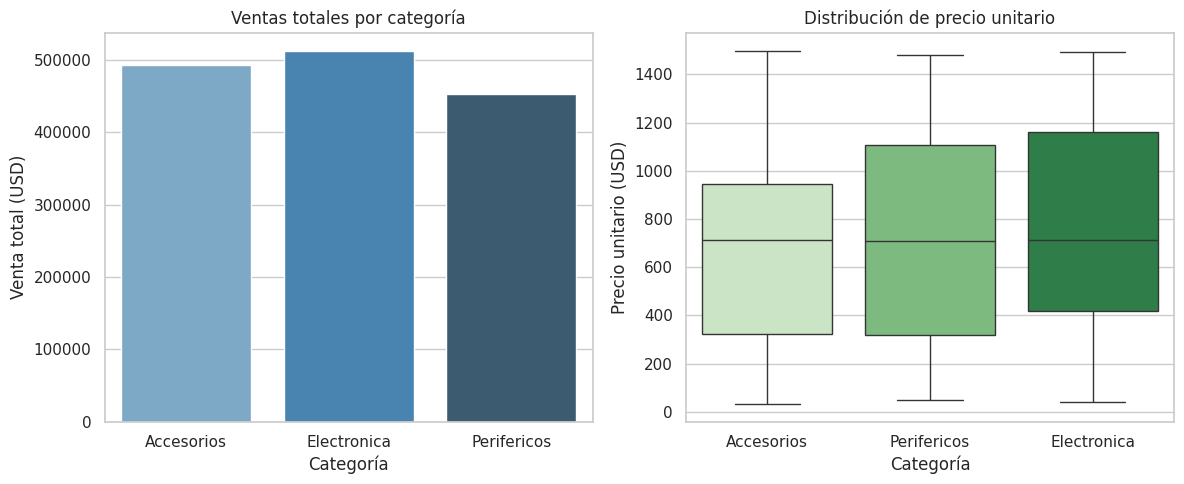

In [54]:
# Prueba DataAnalyst
# ---------------------------------------------------------------------------

analyst = DataAnalyst(df_limpio)

# Probamos cada método por separado antes del pipeline completo
analyst.report_console()
analyst.report_visual()

## Paso 6: Pipeline completo — orquestando las piezas

Ahora conecto todas las clases en secuencia. Esta celda es el punto
de entrada del sistema: instancia los objetos en orden y pasa los datos
de uno al siguiente.

El código principal no conoce los detalles internos de ninguna clase —
solo sabe que todas tienen `.execute()`. Eso es abstracción funcionando
en la práctica.

 PIPELINE DE DATOS — VENTAS
[INFO] [2026-06-22 03:09:33] DataLoader: Iniciando ingesta de datos.
[INFO] [2026-06-22 03:09:33] DataLoader: Archivo verificado: 'ventas.csv'
[INFO] [2026-06-22 03:09:33] DataLoader: Cargando archivo en memoria...
[INFO] [2026-06-22 03:09:33] DataLoader: Carga exitosa — 200 filas | 6 columnas.
[INFO] [2026-06-22 03:09:33] DataCleaner: Iniciando limpieza de datos.
[INFO] [2026-06-22 03:09:33] DataCleaner: Nulos detectados antes de limpiar: 106
[INFO] [2026-06-22 03:09:33] DataCleaner: Columna 'fecha' convertida a datetime.
[INFO] [2026-06-22 03:09:33] DataCleaner: Nulos después de limpiar: 0
[INFO] [2026-06-22 03:09:33] DataCleaner: Limpieza completada.

Resumen post-limpieza:
  shape: (200, 6)
  nulos_por_columna: {'fecha': 0, 'producto': 0, 'categoria': 0, 'cantidad': 0, 'precio_unitario': 0, 'region': 0}
  tipos_de_datos: {'fecha': 'datetime64[ns]', 'producto': 'object', 'categoria': 'object', 'cantidad': 'float64', 'precio_unitario': 'float64', 'region':

/tmp/ipykernel_782/4046160247.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_782/4046160247.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


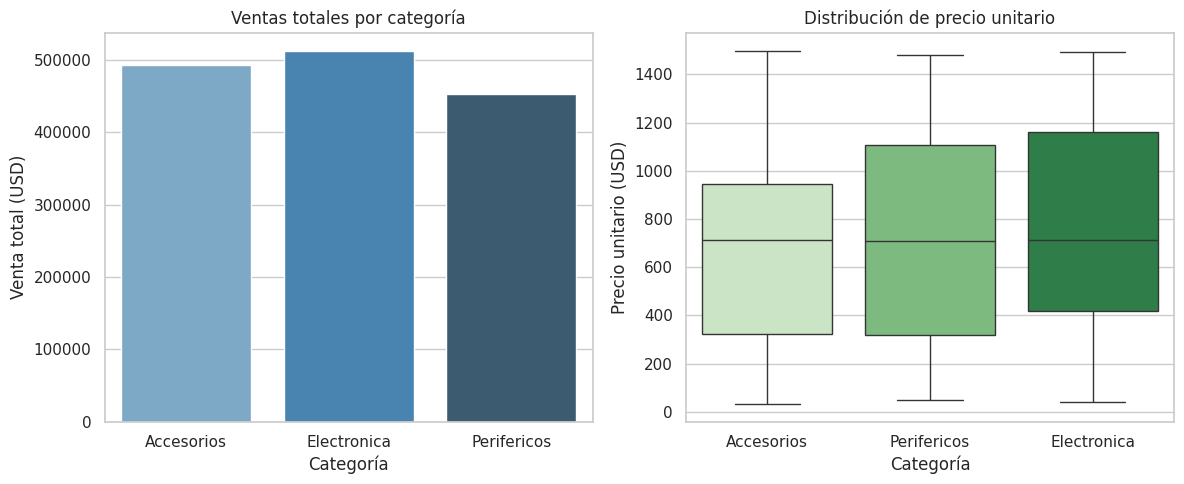


 PIPELINE FINALIZADO CON ÉXITO


In [55]:
# Paso 6: Pipeline completo
# ---------------------------------------------------------------------------

print("=" * 50)
print(" PIPELINE DE DATOS — VENTAS")
print("=" * 50)

# 1. INGESTA — DataLoader carga el CSV
loader = DataLoader("ventas.csv")
df_crudo = loader.execute()

# 2. LIMPIEZA — DataCleaner imputa nulos y convierte tipos
cleaner = DataCleaner(df_crudo)
df_limpio = cleaner.execute()

# Verificamos el resumen del DataFrame limpio via @property
print("\nResumen post-limpieza:")
for clave, valor in cleaner.summary.items():
    print(f"  {clave}: {valor}")

# 3. ANÁLISIS — DataAnalyst genera reportes
analyst = DataAnalyst(df_limpio)
analyst.execute()

print("\n" + "=" * 50)
print(" PIPELINE FINALIZADO CON ÉXITO")
print("=" * 50)

---
# Ejercicio final — Pipeline de empleados

Aplico la misma arquitectura del taller pero adaptada a un nuevo dominio:
gestión de empleados. Reutilizo `DataComponent`, `ValidatorMixin` y
`LoggerMixin` — no los reescribo, ya están definidos arriba.

Lo que construyo:
- `EmployeeLoader` — carga y valida columnas obligatorias del CSV.
- `EmployeeCleaner` — imputa nulos y agrega columna calculada `salario_anual`.
- `EmployeeAnalyst` — reportes en consola y gráfico diferente al del taller.

In [56]:
# Dataset de empleados — generado para el ejercicio final
np.random.seed(7)
n = 150

empleados = {
    "id_empleado": range(1, n + 1),
    "nombre": [f"Empleado_{i}" for i in range(1, n + 1)],
    "departamento": np.random.choice(["Ventas", "IT", "RRHH", "Finanzas", None], n),
    "salario": np.round(np.random.uniform(800, 5000, n), 2),
    "anos_experiencia": np.random.randint(0, 20, n).astype(float),
    "evaluacion": np.random.choice([1, 2, 3, 4, 5, None], n),
    "fecha_ingreso": pd.date_range("2015-01-01", periods=n, freq="15D").astype(str),
}

df_emp = pd.DataFrame(empleados)

# Nulos artificiales para simular datos reales
df_emp.loc[np.random.choice(df_emp.index, 12, replace=False), "salario"] = np.nan
df_emp.loc[np.random.choice(df_emp.index, 8, replace=False), "anos_experiencia"] = np.nan

df_emp.to_csv("empleados.csv", index=False)
print(f"Archivo 'empleados.csv' creado con {len(df_emp)} filas.")
df_emp.head()

Archivo 'empleados.csv' creado con 150 filas.


,id_empleado,nombre,departamento,salario,anos_experiencia,evaluacion,fecha_ingreso
0,1,Empleado_1,None,4085.37,NaN,None,2015-01-01
1,2,Empleado_2,IT,4399.30,14.0,1,2015-01-16
2,3,Empleado_3,Finanzas,941.43,14.0,5,2015-01-31
3,4,Empleado_4,Finanzas,3037.11,4.0,3,2015-02-15
4,5,Empleado_5,None,4147.20,19.0,1,2015-03-02


## Instrucciones

Construye un pipeline para este dataset. Puedes reutilizar los Mixins y la clase abstracta que ya escribiste — no los reescribas, solo importalos o asegurate de que esten en el mismo notebook.

**Lo que debes implementar:**

### 1. `EmployeeLoader`
- Hereda de `DataComponent`, `ValidatorMixin` y `LoggerMixin`.
- Carga el archivo `empleados.csv`.
- **Diferencia respecto al taller:** valida ademas que el DataFrame tenga las columnas `["id_empleado", "salario", "departamento"]` antes de retornarlo. Usa `validate_columns()` del Mixin.

### 2. `EmployeeCleaner`
- Hereda de `DataComponent` y `LoggerMixin`.
- Imputa nulos (misma logica: mediana para numericos, "Desconocido" para texto).
- **Diferencia respecto al taller:** agrega una columna calculada `salario_anual = salario * 12` durante la limpieza.
- Implementa un `@property` llamado `stats` que retorne el salario promedio y mediano por departamento.

### 3. `EmployeeAnalyst`
- Hereda de `DataComponent` y `LoggerMixin`.
- `report_console()`: muestra el salario promedio por departamento y el top 5 de empleados mejor pagados.
- `report_visual()`: genera **al menos un grafico diferente** a los del taller (por ejemplo: boxplot de salario por departamento, o scatter de anos_experiencia vs salario).

### 4. Pipeline final
- Conecta los tres objetos en secuencia en una sola celda.

---

**Pista:** si algo no funciona, revisa que `execute()` este retornando el DataFrame — es el error mas comun al encadenar el pipeline.


In [57]:
# EmployeeLoader
# ---------------------------------------------------------------------------

class EmployeeLoader(DataComponent, ValidatorMixin, LoggerMixin):
    """
    Componente de ingesta para el dataset de empleados.
    Valida existencia del archivo y columnas obligatorias antes de retornar.
    """

    COLUMNAS_REQUERIDAS = ["id_empleado", "salario", "departamento"]

    def __init__(self, file_path: str):
        super().__init__()
        self.__file_path = file_path  # Atributo privado — encapsulamiento

    def execute(self) -> pd.DataFrame:
        """
        Valida el archivo, lo carga y verifica columnas obligatorias.
        Retorna un DataFrame de empleados.
        """
        self.log("Iniciando ingesta del dataset de empleados.")

        # 1. Verificamos que el archivo existe
        self.validate_file(self.__file_path)
        self.log(f"Archivo verificado: '{self.__file_path}'")

        # 2. Cargamos el CSV
        self.log("Cargando archivo en memoria...")
        df = pd.read_csv(self.__file_path)

        # 3. Validamos columnas obligatorias — diferencia clave vs DataLoader
        self.validate_columns(df, self.COLUMNAS_REQUERIDAS)
        self.log(f"Columnas obligatorias presentes: {self.COLUMNAS_REQUERIDAS}")

        self.log(f"Carga exitosa — {df.shape[0]} filas | {df.shape[1]} columnas.")
        return df

In [58]:
# Prueba EmployeeLoader
# ---------------------------------------------------------------------------

# Caso 1: carga exitosa
emp_loader = EmployeeLoader("empleados.csv")
df_emp_crudo = emp_loader.execute()
print(df_emp_crudo.head())

# Caso 2: columnas faltantes
try:
    df_incompleto = pd.DataFrame({"id_empleado": [1, 2]})
    emp_loader.validate_columns(df_incompleto, EmployeeLoader.COLUMNAS_REQUERIDAS)
except ValueError as e:
    print("Error controlado:", e)

[INFO] [2026-06-22 03:09:33] EmployeeLoader: Iniciando ingesta del dataset de empleados.
[INFO] [2026-06-22 03:09:33] EmployeeLoader: Archivo verificado: 'empleados.csv'
[INFO] [2026-06-22 03:09:33] EmployeeLoader: Cargando archivo en memoria...
[INFO] [2026-06-22 03:09:33] EmployeeLoader: Columnas obligatorias presentes: ['id_empleado', 'salario', 'departamento']
[INFO] [2026-06-22 03:09:33] EmployeeLoader: Carga exitosa — 150 filas | 7 columnas.
   id_empleado      nombre departamento  salario  anos_experiencia  \
0            1  Empleado_1          NaN  4085.37               NaN   
1            2  Empleado_2           IT  4399.30              14.0   
2            3  Empleado_3     Finanzas   941.43              14.0   
3            4  Empleado_4     Finanzas  3037.11               4.0   
4            5  Empleado_5          NaN  4147.20              19.0   

   evaluacion fecha_ingreso  
0         NaN    2015-01-01  
1         1.0    2015-01-16  
2         5.0    2015-01-31  
3      

In [59]:
# EmployeeCleaner
# ---------------------------------------------------------------------------

class EmployeeCleaner(DataComponent, LoggerMixin):
    """
    Componente de transformación para el dataset de empleados.
    Imputa nulos, agrega salario_anual y expone estadísticas por @property.
    """

    def __init__(self, df: pd.DataFrame):
        super().__init__()
        self.__df = df.copy()  # Copia defensiva — no modificamos el original

    @property
    def stats(self) -> pd.DataFrame:
        """
        Retorna salario promedio y mediano agrupado por departamento.
        Acceso de solo lectura sin necesidad de llamar a ningún método.
        """
        return (
            self.__df.groupby("departamento")["salario"]
            .agg(promedio="mean", mediana="median")
            .round(2)
        )

    def execute(self) -> pd.DataFrame:
        """
        Imputa nulos numéricos con mediana, texto con 'Desconocido',
        convierte fecha_ingreso a datetime y agrega columna salario_anual.
        Retorna el DataFrame limpio.
        """
        self.log("Iniciando limpieza del dataset de empleados.")

        nulos_antes = self.__df.isnull().sum().sum()
        self.log(f"Nulos detectados antes de limpiar: {nulos_antes}")

        # 1. Imputación de columnas numéricas con la mediana
        num_cols = self.__df.select_dtypes(include=["number"]).columns
        for col in num_cols:
            if self.__df[col].isnull().any():
                self.__df[col] = self.__df[col].fillna(self.__df[col].median())

        # 2. Imputación de columnas de texto con "Desconocido"
        cat_cols = self.__df.select_dtypes(include=["object"]).columns
        for col in cat_cols:
            if self.__df[col].isnull().any():
                self.__df[col] = self.__df[col].fillna("Desconocido")

        # 3. Conversión de fecha_ingreso a datetime
        if "fecha_ingreso" in self.__df.columns:
            self.__df["fecha_ingreso"] = pd.to_datetime(self.__df["fecha_ingreso"])
            self.log("Columna 'fecha_ingreso' convertida a datetime.")

        # 4. Columna calculada — diferencia clave vs DataCleaner
        self.__df["salario_anual"] = self.__df["salario"] * 12
        self.log("Columna 'salario_anual' agregada correctamente.")

        nulos_despues = self.__df.isnull().sum().sum()
        self.log(f"Nulos después de limpiar: {nulos_despues}")
        self.log("Limpieza completada.")

        return self.__df

In [60]:
# Prueba EmployeeCleaner
# ---------------------------------------------------------------------------

emp_cleaner = EmployeeCleaner(df_emp_crudo)
df_emp_limpio = emp_cleaner.execute()

# Verificamos la columna calculada
print("Columna salario_anual agregada:")
print(df_emp_limpio[["nombre", "salario", "salario_anual"]].head())

# Verificamos el @property stats
print("\nEstadísticas salariales por departamento:")
print(emp_cleaner.stats)

[INFO] [2026-06-22 03:09:33] EmployeeCleaner: Iniciando limpieza del dataset de empleados.
[INFO] [2026-06-22 03:09:33] EmployeeCleaner: Nulos detectados antes de limpiar: 85
[INFO] [2026-06-22 03:09:33] EmployeeCleaner: Columna 'fecha_ingreso' convertida a datetime.
[INFO] [2026-06-22 03:09:33] EmployeeCleaner: Columna 'salario_anual' agregada correctamente.
[INFO] [2026-06-22 03:09:33] EmployeeCleaner: Nulos después de limpiar: 0
[INFO] [2026-06-22 03:09:33] EmployeeCleaner: Limpieza completada.
Columna salario_anual agregada:
       nombre  salario  salario_anual
0  Empleado_1  4085.37       49024.44
1  Empleado_2  4399.30       52791.60
2  Empleado_3   941.43       11297.16
3  Empleado_4  3037.11       36445.32
4  Empleado_5  4147.20       49766.40

Estadísticas salariales por departamento:
              promedio  mediana
departamento                   
Desconocido    2967.87  3012.69
Finanzas       2700.55  3012.69
IT             3348.98  3441.18
RRHH           3071.79  2877.12
Ve

In [61]:
# EmployeeAnalyst
# ---------------------------------------------------------------------------

class EmployeeAnalyst(DataComponent, LoggerMixin):
    """
    Componente de análisis para el dataset de empleados.
    Implementa polimorfismo con dos métodos de reporte intercambiables.
    """

    def __init__(self, df: pd.DataFrame):
        super().__init__()
        self.__df = df

    def execute(self):
        """
        Ejecuta el reporte completo: primero consola, luego visual.
        """
        self.report_console()
        self.report_visual()

    def report_console(self):
        """
        Muestra salario promedio por departamento y top 5 empleados
        mejor pagados por salario anual.
        """
        self.log("Generando reporte en consola.")

        print("\n" + "=" * 50)
        print(" REPORTE DESCRIPTIVO — DATASET DE EMPLEADOS")
        print("=" * 50)

        # Salario promedio por departamento
        print("\nSalario promedio por departamento:")
        promedio_depto = (
            self.__df.groupby("departamento")["salario"]
            .mean()
            .round(2)
            .sort_values(ascending=False)
        )
        print(promedio_depto)

        # Top 5 empleados mejor pagados
        print("\nTop 5 empleados mejor pagados:")
        top5 = (
            self.__df[["nombre", "departamento", "salario_anual"]]
            .sort_values("salario_anual", ascending=False)
            .head(5)
            .reset_index(drop=True)
        )
        print(top5)
        print("=" * 50 + "\n")

    def report_visual(self):
        """
        Genera dos gráficos distintos al taller:
        1. Boxplot de salario por departamento.
        2. Scatter de años de experiencia vs salario coloreado por departamento.
        """
        self.log("Generando reporte visual.")

        sns.set_theme(style="whitegrid")
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        # Gráfico 1: boxplot de salario por departamento
        sns.boxplot(
            data=self.__df,
            x="departamento",
            y="salario",
            ax=axes[0],
            palette="Blues"
        )
        axes[0].set_title("Distribución de salario por departamento")
        axes[0].set_xlabel("Departamento")
        axes[0].set_ylabel("Salario (USD)")
        axes[0].tick_params(axis="x", rotation=15)

        # Gráfico 2: scatter años de experiencia vs salario
        sns.scatterplot(
            data=self.__df,
            x="anos_experiencia",
            y="salario",
            hue="departamento",
            ax=axes[1],
            palette="Set2",
            alpha=0.7
        )
        axes[1].set_title("Experiencia vs Salario por departamento")
        axes[1].set_xlabel("Años de experiencia")
        axes[1].set_ylabel("Salario (USD)")
        axes[1].legend(title="Departamento", bbox_to_anchor=(1, 1))

        plt.tight_layout()
        plt.show()

[INFO] [2026-06-22 03:09:33] EmployeeAnalyst: Generando reporte en consola.

 REPORTE DESCRIPTIVO — DATASET DE EMPLEADOS

Salario promedio por departamento:
departamento
IT             3348.98
RRHH           3071.79
Desconocido    2967.87
Finanzas       2700.55
Ventas         2614.70
Name: salario, dtype: float64

Top 5 empleados mejor pagados:
         nombre departamento  salario_anual
0   Empleado_93  Desconocido       59427.12
1  Empleado_138           IT       59255.04
2    Empleado_6           IT       58747.08
3   Empleado_88         RRHH       58663.20
4   Empleado_89     Finanzas       57751.32

[INFO] [2026-06-22 03:09:33] EmployeeAnalyst: Generando reporte visual.


/tmp/ipykernel_782/673542857.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


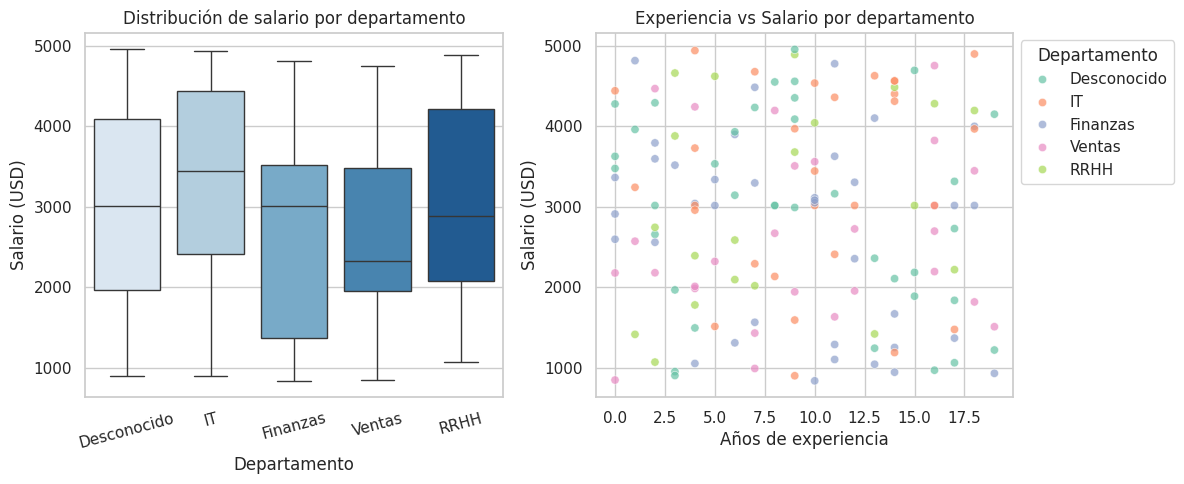

In [62]:
# Prueba EmployeeAnalyst
# ---------------------------------------------------------------------------

emp_analyst = EmployeeAnalyst(df_emp_limpio)

# Probamos cada método por separado
emp_analyst.report_console()
emp_analyst.report_visual()

 PIPELINE DE DATOS — EMPLEADOS
[INFO] [2026-06-22 03:09:34] EmployeeLoader: Iniciando ingesta del dataset de empleados.
[INFO] [2026-06-22 03:09:34] EmployeeLoader: Archivo verificado: 'empleados.csv'
[INFO] [2026-06-22 03:09:34] EmployeeLoader: Cargando archivo en memoria...
[INFO] [2026-06-22 03:09:34] EmployeeLoader: Columnas obligatorias presentes: ['id_empleado', 'salario', 'departamento']
[INFO] [2026-06-22 03:09:34] EmployeeLoader: Carga exitosa — 150 filas | 7 columnas.
[INFO] [2026-06-22 03:09:34] EmployeeCleaner: Iniciando limpieza del dataset de empleados.
[INFO] [2026-06-22 03:09:34] EmployeeCleaner: Nulos detectados antes de limpiar: 85
[INFO] [2026-06-22 03:09:34] EmployeeCleaner: Columna 'fecha_ingreso' convertida a datetime.
[INFO] [2026-06-22 03:09:34] EmployeeCleaner: Columna 'salario_anual' agregada correctamente.
[INFO] [2026-06-22 03:09:34] EmployeeCleaner: Nulos después de limpiar: 0
[INFO] [2026-06-22 03:09:34] EmployeeCleaner: Limpieza completada.

Estadísticas 

/tmp/ipykernel_782/673542857.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


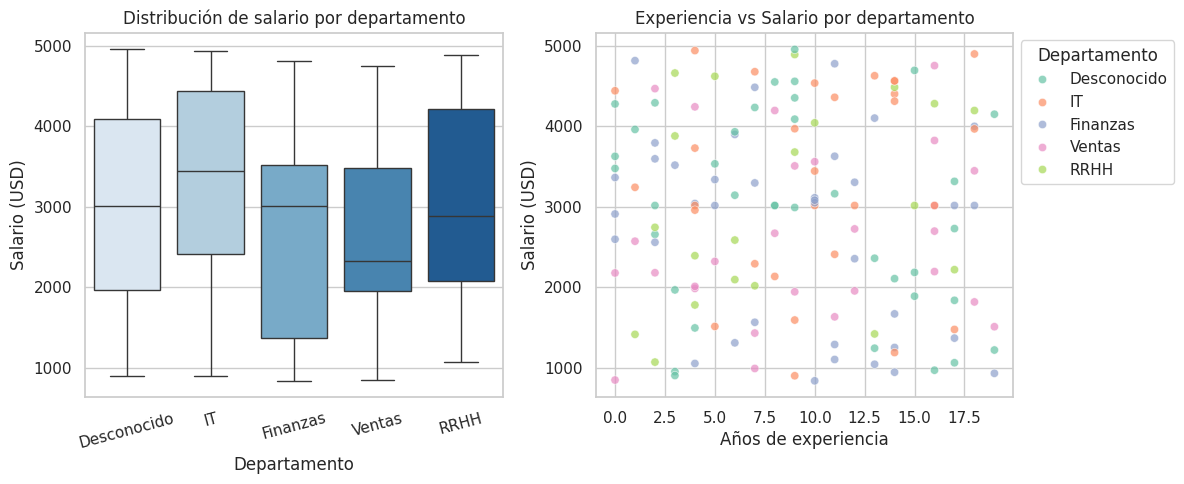


 PIPELINE DE EMPLEADOS FINALIZADO CON ÉXITO
Archivo temporal 'ventas.csv' eliminado.
Archivo temporal 'empleados.csv' eliminado.


In [63]:
# Pipeline final de empleados
# ---------------------------------------------------------------------------

print("=" * 50)
print(" PIPELINE DE DATOS — EMPLEADOS")
print("=" * 50)

# 1. INGESTA — EmployeeLoader carga y valida columnas
emp_loader = EmployeeLoader("empleados.csv")
df_emp_crudo = emp_loader.execute()

# 2. LIMPIEZA — EmployeeCleaner imputa nulos y agrega salario_anual
emp_cleaner = EmployeeCleaner(df_emp_crudo)
df_emp_limpio = emp_cleaner.execute()

# Verificamos estadísticas via @property stats
print("\nEstadísticas salariales por departamento:")
print(emp_cleaner.stats)

# 3. ANÁLISIS — EmployeeAnalyst genera reportes
emp_analyst = EmployeeAnalyst(df_emp_limpio)
emp_analyst.execute()

print("\n" + "=" * 50)
print(" PIPELINE DE EMPLEADOS FINALIZADO CON ÉXITO")
print("=" * 50)

# Limpieza de archivos temporales
for archivo in ["ventas.csv", "empleados.csv"]:
    if os.path.exists(archivo):
        os.remove(archivo)
        print(f"Archivo temporal '{archivo}' eliminado.")

---
# Cierre del taller

Apliqué los cuatro pilares de la POO en un contexto real de ciencia de datos:

| Concepto | Dónde lo apliqué |
|---|---|
| **Abstracción** | `DataComponent` con `@abstractmethod execute()` |
| **Herencia** | Todas las clases heredan `DataComponent` y los Mixins |
| **Encapsulamiento** | Atributos privados `__file_path`, `__df` y acceso por `@property` |
| **Polimorfismo** | `report_console()` y `report_visual()` como formas distintas de analizar |

La arquitectura construida — clase abstracta + Mixins + clases concretas +
pipeline orquestador — es el mismo patrón que usan librerías reales como
`scikit-learn`, donde todos los modelos exponen `.fit()` y `.predict()`.